# Health Insurance Fraud Detection (Model Deployment With Most features)

Import required Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import plotly.express as px
import scipy as scipy
import math
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegressionCV
from sklearn import metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report

In [2]:
X = pd.read_csv("Training_data_X.csv")
y = pd.read_csv("Training_data_Y.csv")

In [3]:
X.shape, type(X), y.shape, type(y)

((5410, 299),
 pandas.core.frame.DataFrame,
 (5410, 1),
 pandas.core.frame.DataFrame)

In [4]:
X.head()

,InscClaimAmtReimbursed,DeductibleAmtPaid,RenalDiseaseIndicator,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,...,ClmCount_Provider_BeneID_ClmDiagnosisCode_9_ClmProcedureCode_3,ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_1,ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_2,ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_3,Gender_1,Race_2,Race_3,Race_5,Admitted?_1,Is_Alive?_1
0,104640,5340.0,8,15,19,17,5,10,9,21,...,0.0,0.0,0.0,0.0,9.0,4.0,0.0,0.0,5.0,0.0
1,605670,66286.0,29,56,80,64,10,41,54,100,...,0.0,3.0,1.0,0.0,54.0,24.0,0.0,1.0,62.0,1.0
2,52170,310.0,23,64,88,50,16,41,63,105,...,0.0,0.0,0.0,0.0,46.0,24.0,5.0,0.0,0.0,1.0
3,280910,3700.0,259,426,680,507,165,295,485,799,...,0.0,0.0,0.0,0.0,511.0,262.0,10.0,0.0,0.0,4.0
4,33710,3264.0,11,26,40,22,12,16,29,49,...,0.0,0.0,0.0,0.0,34.0,14.0,0.0,0.0,3.0,1.0


In [5]:
y.head()

,PotentialFraud
0,0
1,1
2,0
3,1
4,0


## **`Train Test Split` :: Creating TRAIN and VALIDATION sets.**

   * **`Reasoning`** :: These sets will be used for measurng the performance of ML Models.

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=39)

In [8]:
# Checking shape of each set
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((4328, 299), (1082, 299), (4328, 1), (1082, 1))

In [9]:
# Checking count of tgt labels in y_train
y_train.value_counts()

PotentialFraud
0                 3923
1                  405
dtype: int64

In [10]:
# Checking count of tgt labels in y_test
y_test.value_counts()

PotentialFraud
0                 981
1                 101
dtype: int64

In [11]:
pd.set_option('display.max_columns',30)
label_font_dict = {'family':'sans-serif','size':13.5,'color':'brown','style':'italic'}
title_font_dict = {'family':'sans-serif','size':16.5,'color':'Blue','style':'italic'}

# **`Standardizing TRAIN & TEST sets`** 
## **Bringing every feature into the same scale.**

In [12]:
from sklearn.preprocessing import RobustScaler

In [13]:
# Standardize the data (train and test)
robust_scaler = RobustScaler()
robust_scaler.fit(X_train)
X_train_std = robust_scaler.transform(X_train)
X_test_std = robust_scaler.transform(X_test)

In [14]:
def validate_model(clf, x_train, x_test, y_train, y_test):
    y_train_pred = pred_prob(clf, x_train)
    
    y_test_pred = pred_prob(clf, x_test)
    
    train_fpr, train_tpr, tr_thresholds = roc_curve(y_train, y_train_pred)
    test_fpr, test_tpr, te_thresholds = roc_curve(y_test, y_test_pred)
    
    train_auc = auc(train_fpr, train_tpr)
    print("Train AUC = {}".format(train_auc))
    test_auc = auc(test_fpr, test_tpr)
    print("Test AUC = {}".format(test_auc))
     
    draw_roc(train_fpr, train_tpr, test_fpr, test_tpr)
    
    best_t = find_best_threshold(tr_thresholds, train_fpr, train_tpr)
    
    train_prediction, test_prediction = draw_confusion_matrix(best_t, x_train, x_test, y_train, y_test, y_train_pred, y_test_pred)
    
    
    train_f1_score = f1_score(y_train, train_prediction)
    test_f1_score = f1_score(y_test, test_prediction)
    cr = classification_report(y_test, test_prediction)
    acc_scr = accuracy_score(y_test, test_prediction)

   
    return test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr

In [15]:
def pred_prob(clf, data): 
    
    y_pred = clf.predict_proba(data)[:,1]
    return y_pred

def draw_roc(train_fpr, train_tpr, test_fpr, test_tpr):
    
    train_auc = auc(train_fpr, train_tpr)
    test_auc = auc(test_fpr, test_tpr)
    with plt.style.context('seaborn-poster'):
      plt.plot(train_fpr, train_tpr, label="Train AUC ="+"{:.4f}".format(train_auc), color='blue')
      plt.plot(test_fpr, test_tpr, label="Test AUC ="+"{:.4f}".format(test_auc), color='red')
      plt.legend()
      plt.xlabel("False Positive Rate(FPR)", fontdict=label_font_dict)
      plt.ylabel("True Positive Rate(TPR)", fontdict=label_font_dict)
      plt.title("Area Under Curve", fontdict=title_font_dict)
      plt.grid(b=True, which='major', color='lightgrey', linestyle='--')
      plt.minorticks_on()
      plt.show()
    
def find_best_threshold(threshold, fpr, tpr):
    t = threshold[np.argmax(tpr * (1-fpr))]
    return t

def predict_with_best_t(proba, threshold):
    predictions = []
    for i in proba:
        if i>=threshold:
            predictions.append(1)
        else:
            predictions.append(0)
    return predictions

def draw_confusion_matrix(best_t, x_train, x_test, y_train, y_test, y_train_pred, y_test_pred):
    fig, ax = plt.subplots(1,2, figsize=(20,6))

    train_prediction = predict_with_best_t(y_train_pred, best_t)
    cm = confusion_matrix(y_train, train_prediction)
    with plt.style.context('seaborn'):
        sns.heatmap(cm, annot=True, fmt='d', ax=ax[0], cmap='viridis')
        ax[0].set_title('Train Dataset Confusion Matrix', fontdict=title_font_dict)
        ax[0].set_xlabel("Predicted Label", fontdict=label_font_dict)
        ax[0].set_ylabel("Actual Label", fontdict=label_font_dict)

    test_prediction = predict_with_best_t(y_test_pred, best_t)
    cm = confusion_matrix(y_test, test_prediction)
    with plt.style.context('seaborn'):
        sns.heatmap(cm, annot=True, fmt='d', ax=ax[1], cmap='summer')
        ax[1].set_title('Test Dataset Confusion Matrix', fontdict=title_font_dict)
        ax[1].set_xlabel("Predicted Label", fontdict=label_font_dict)
        ax[1].set_ylabel("Actual Label", fontdict=label_font_dict)
    
    plt.show()
    
    return train_prediction, test_prediction

# **`Model Training`**

  **-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Now our data is clean. So let's deploy model on it-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--XgBoost Classifier-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [16]:
from xgboost import XGBClassifier

xgb = XGBClassifier()
xgb.fit(X_train_std, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 1.0
Test AUC = 0.9418859317124372


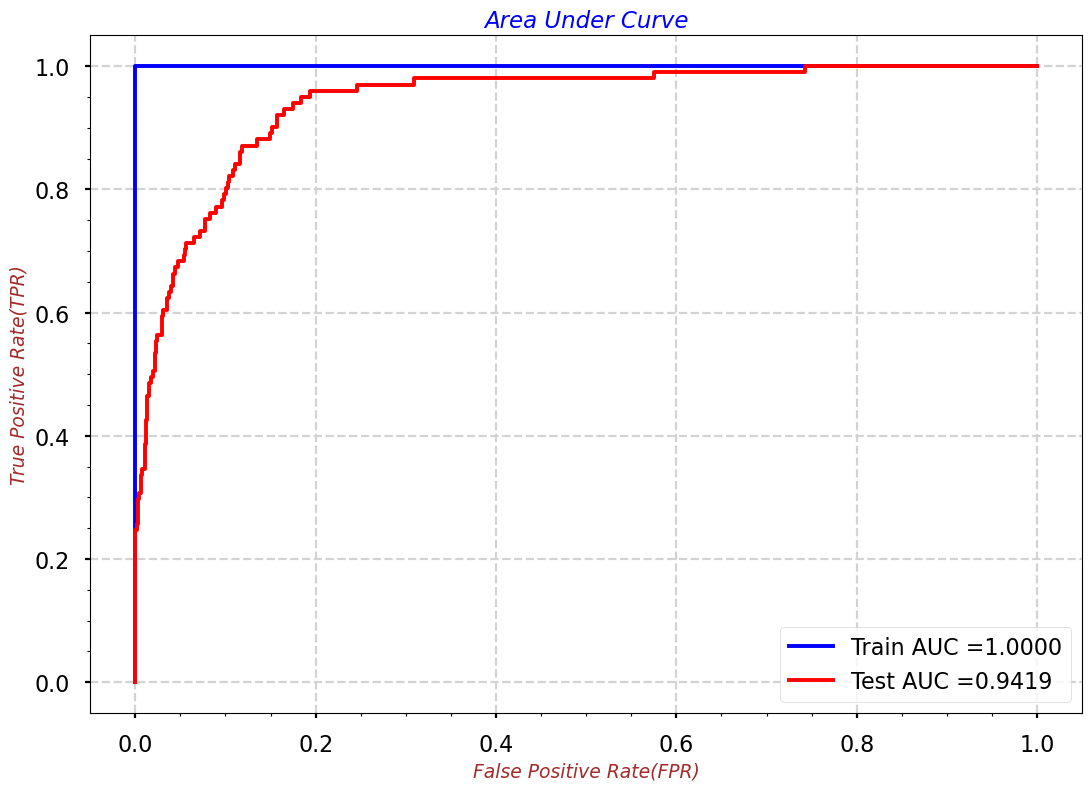

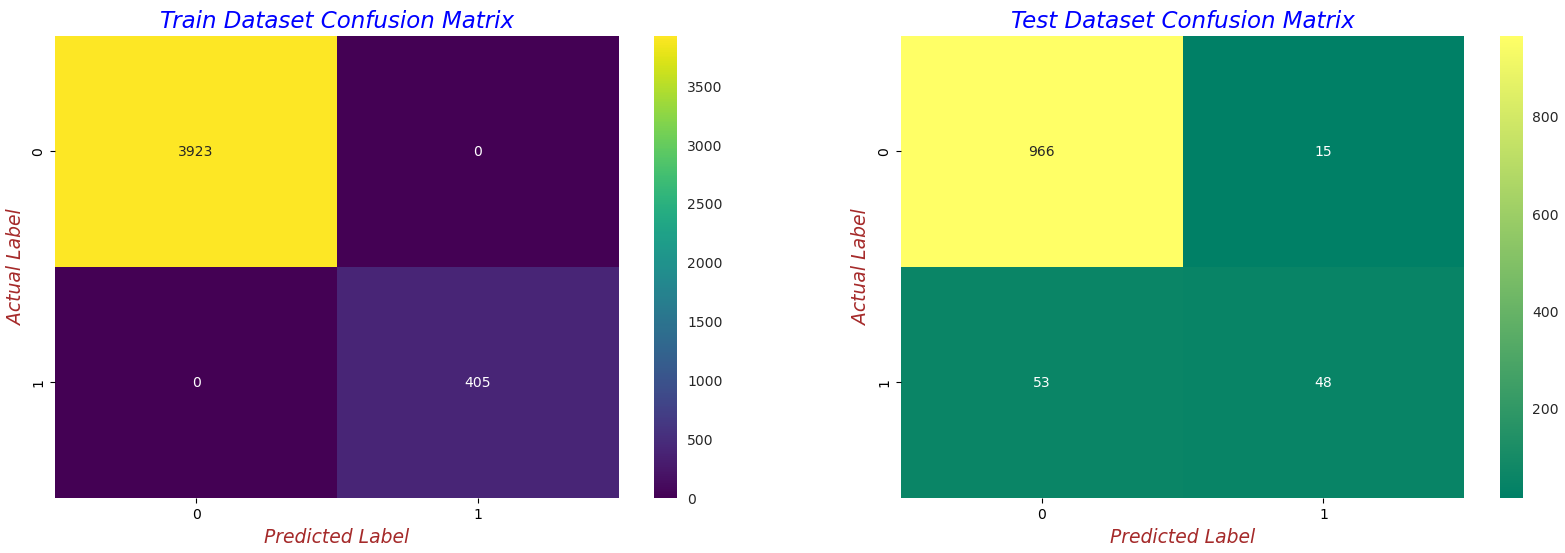



Best Threshold = 0.6826
Model AUC is : 0.9419
Model Train F1 Score is : 1.0000
Model Test F1 Score is : 0.5854
Classification Report is: 
               precision    recall  f1-score   support

           0       0.95      0.98      0.97       981
           1       0.76      0.48      0.59       101

    accuracy                           0.94      1082
   macro avg       0.85      0.73      0.78      1082
weighted avg       0.93      0.94      0.93      1082



In [17]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(xgb, X_train_std, X_test_std, y_train, y_test)

print("\n")
xgb_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

In [18]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': xgb.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.Features.head()

0       InscClaimAmtReimbursed
1            DeductibleAmtPaid
2        RenalDiseaseIndicator
3        ChronicCond_Alzheimer
4    ChronicCond_KidneyDisease
Name: Features, dtype: object

In [19]:
top_20_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:20]
top_20_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:20]

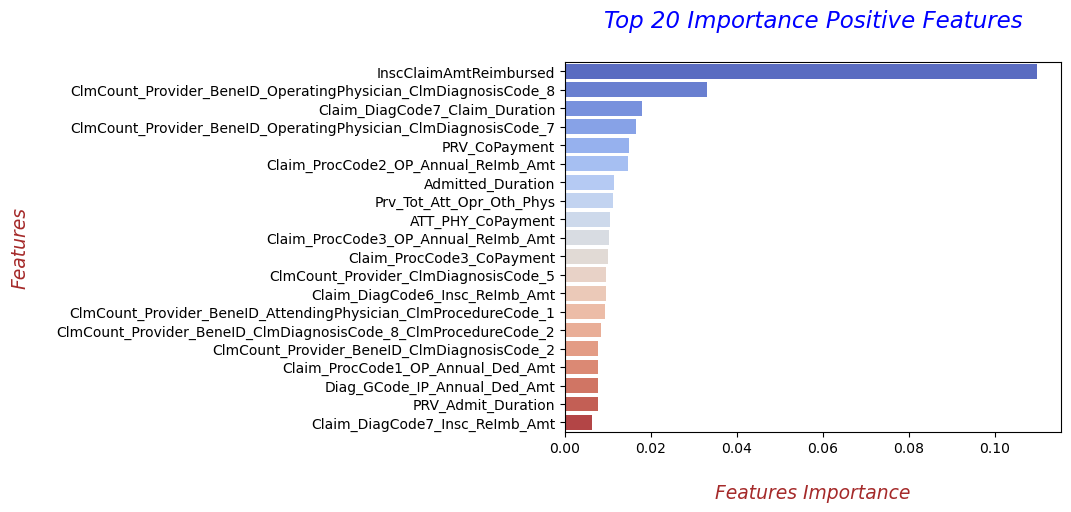

In [20]:
sns.barplot(y=top_20_pos_feats, x=top_20_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 20 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

In [21]:
bene_test_df = pd.read_csv("Test_Beneficiarydata-1542969243754.csv")
ip_test_df = pd.read_csv("Test_Inpatientdata-1542969243754.csv")
op_test_df = pd.read_csv("Test_Outpatientdata-1542969243754.csv")
tgt_test_df = pd.read_csv("Test-1542969243754.csv")

In [35]:
tgt_test_df.head(15)

,Provider
0,PRV51002
1,PRV51006
2,PRV51009
3,PRV51010
4,PRV51018
5,PRV51019
6,PRV51020
7,PRV51022
8,PRV51028
9,PRV51033


In [22]:
def test_data(xgb, bene_test_df,ip_test_df,op_test_df,tgt_test_df):
    ip_test_df["Admitted?"] = 1
    op_test_df["Admitted?"] = 0
    common_cols = [col for col in ip_test_df.columns if col in op_test_df.columns]
    test_ip_op_df = pd.merge(left=ip_test_df, right=op_test_df, left_on=common_cols, right_on=common_cols, how="outer")
    test_ip_op_bene_df = pd.merge(left=test_ip_op_df, right=bene_test_df, left_on='BeneID', right_on='BeneID',how='inner')
    test_iobp_df = pd.merge(left=test_ip_op_bene_df, right=tgt_test_df, left_on='Provider', right_on='Provider',how='inner')
    prvs_claims_df = pd.DataFrame(test_iobp_df.groupby(['Provider'])['ClaimID'].count()).reset_index()
    prvs_claims_tgt_lbls_df = pd.merge(left=prvs_claims_df, right=tgt_test_df, on='Provider', how='inner')
    test_iobp_df['DOB'] = pd.to_datetime(test_iobp_df['DOB'], format="%Y-%m-%d")
    test_iobp_df['DOD'] = pd.to_datetime(test_iobp_df['DOD'], format="%Y-%m-%d")
    test_iobp_df['Is_Alive?'] = test_iobp_df['DOD'].apply(lambda val: 'No' if val != val else 'Yes')
    test_iobp_df['ClaimStartDt'] = pd.to_datetime(test_iobp_df['ClaimStartDt'], format="%Y-%m-%d")
    test_iobp_df['ClaimEndDt'] = pd.to_datetime(test_iobp_df['ClaimEndDt'], format="%Y-%m-%d")
    test_iobp_df['Claim_Duration'] = (test_iobp_df['ClaimEndDt'] - test_iobp_df['ClaimStartDt']).dt.days
    test_iobp_df['AdmissionDt'] = pd.to_datetime(test_iobp_df['AdmissionDt'], format="%Y-%m-%d")
    test_iobp_df['DischargeDt'] = pd.to_datetime(test_iobp_df['DischargeDt'], format="%Y-%m-%d")
    test_iobp_df['Admitted_Duration'] = (test_iobp_df['DischargeDt'] - test_iobp_df['AdmissionDt']).dt.days
    test_iobp_df['DOD'].fillna(value=test_iobp_df['DOD'].max(), inplace=True)
    test_iobp_df['Bene_Age'] = round(((test_iobp_df['DOD'] - test_iobp_df['DOB']).dt.days)/365,1)
    test_iobp_df['Att_Phy_tot_claims'] = test_iobp_df.groupby(['AttendingPhysician'])['ClaimID'].transform('count')
    test_iobp_df['Opr_Phy_tot_claims'] = test_iobp_df.groupby(['OperatingPhysician'])['ClaimID'].transform('count')
    test_iobp_df['Oth_Phy_tot_claims'] = test_iobp_df.groupby(['OtherPhysician'])['ClaimID'].transform('count')
    test_iobp_df['Att_Phy_tot_claims'].fillna(value=0, inplace=True)
    test_iobp_df['Opr_Phy_tot_claims'].fillna(value=0, inplace=True)
    test_iobp_df['Oth_Phy_tot_claims'].fillna(value=0, inplace=True)
    test_iobp_df['Att_Opr_Oth_Phy_Tot_Claims'] = test_iobp_df['Att_Phy_tot_claims'] + test_iobp_df['Opr_Phy_tot_claims'] + test_iobp_df['Oth_Phy_tot_claims']
    test_iobp_df.drop(['Att_Phy_tot_claims', 'Opr_Phy_tot_claims', 'Oth_Phy_tot_claims'], axis=1, inplace=True)
    test_iobp_df["Prv_Tot_Att_Phy"] = test_iobp_df.groupby(['Provider'])['AttendingPhysician'].transform('count')
    test_iobp_df["Prv_Tot_Opr_Phy"] = test_iobp_df.groupby(['Provider'])['OperatingPhysician'].transform('count')
    test_iobp_df["Prv_Tot_Oth_Phy"] = test_iobp_df.groupby(['Provider'])['OtherPhysician'].transform('count')
    test_iobp_df['Prv_Tot_Att_Opr_Oth_Phys'] = test_iobp_df['Prv_Tot_Att_Phy'] + test_iobp_df['Prv_Tot_Opr_Phy'] + test_iobp_df['Prv_Tot_Oth_Phy']
    test_iobp_df.drop(['Prv_Tot_Att_Phy', 'Prv_Tot_Opr_Phy', 'Prv_Tot_Oth_Phy'], axis=1, inplace=True)
    test_iobp_df['PRV_Tot_Admit_DCodes'] = test_iobp_df.groupby(['Provider'])['ClmAdmitDiagnosisCode'].transform('nunique')
    test_iobp_df['PRV_Tot_DGrpCodes'] = test_iobp_df.groupby(['Provider'])['DiagnosisGroupCode'].transform('nunique')
    test_iobp_df['DOB_Year'] = test_iobp_df['DOB'].dt.year
    test_iobp_df['PRV_Tot_Unq_DOB_Years'] = test_iobp_df.groupby(['Provider'])['DOB_Year'].transform('nunique')
    test_iobp_df.drop(['DOB_Year'], axis=1, inplace=True)
    test_iobp_df['PRV_Bene_Age_Sum'] = test_iobp_df.groupby(['Provider'])['Bene_Age'].transform('sum')
    test_iobp_df['PRV_Insc_Clm_ReImb_Amt'] = test_iobp_df.groupby(['Provider'])['InscClaimAmtReimbursed'].transform('sum')
    test_iobp_df['RenalDiseaseIndicator'] = test_iobp_df['RenalDiseaseIndicator'].apply(lambda val: 1 if val == "Y" else 0)
    test_iobp_df['PRV_Tot_RKD_Patients'] = test_iobp_df.groupby(['Provider'])['RenalDiseaseIndicator'].transform('sum')
    test_iobp_df.drop(['NoOfMonths_PartACov', 'NoOfMonths_PartBCov'], axis=1, inplace=True)
    test_iobp_df['Admitted_Duration'].fillna(value=0,inplace=True)
    test_iobp_df["PRV_CoPayment"] = test_iobp_df.groupby('Provider')['DeductibleAmtPaid'].transform('sum')
    test_iobp_df["PRV_IP_Annual_ReImb_Amt"] = test_iobp_df.groupby('Provider')['IPAnnualReimbursementAmt'].transform('sum')
    test_iobp_df["PRV_IP_Annual_Ded_Amt"] = test_iobp_df.groupby('Provider')['IPAnnualDeductibleAmt'].transform('sum')
    test_iobp_df["PRV_OP_Annual_ReImb_Amt"] = test_iobp_df.groupby('Provider')['OPAnnualReimbursementAmt'].transform('sum')
    test_iobp_df["PRV_OP_Annual_Ded_Amt"] = test_iobp_df.groupby('Provider')['OPAnnualDeductibleAmt'].transform('sum')
    test_iobp_df["PRV_Admit_Duration"] = test_iobp_df.groupby('Provider')['Admitted_Duration'].transform('sum')
    test_iobp_df["PRV_Claim_Duration"] = test_iobp_df.groupby('Provider')['Claim_Duration'].transform('sum')
    def create_agg_feats(grp_col, feat_name, operation='sum'):
        feat_1 = feat_name + "_Insc_ReImb_Amt"
        test_iobp_df[feat_1] = test_iobp_df.groupby(grp_col)['InscClaimAmtReimbursed'].transform(operation)

        feat_2 = feat_name + "_CoPayment"
        test_iobp_df[feat_2] = test_iobp_df.groupby(grp_col)['DeductibleAmtPaid'].transform(operation)

        feat_3 = feat_name + "_IP_Annual_ReImb_Amt"
        test_iobp_df[feat_3] = test_iobp_df.groupby(grp_col)['IPAnnualReimbursementAmt'].transform(operation)

        feat_4 = feat_name + "_IP_Annual_Ded_Amt"
        test_iobp_df[feat_4] = test_iobp_df.groupby(grp_col)['IPAnnualDeductibleAmt'].transform(operation)

        feat_5 = feat_name + "_OP_Annual_ReImb_Amt"
        test_iobp_df[feat_5] = test_iobp_df.groupby(grp_col)['OPAnnualReimbursementAmt'].transform(operation)

        feat_6 = feat_name + "_OP_Annual_Ded_Amt"
        test_iobp_df[feat_6] = test_iobp_df.groupby(grp_col)['OPAnnualDeductibleAmt'].transform(operation)

        feat_7 = feat_name + "_Admit_Duration"
        test_iobp_df[feat_7] = test_iobp_df.groupby(grp_col)['Admitted_Duration'].transform(operation)

        feat_8 = feat_name + "_Claim_Duration"
        test_iobp_df[feat_8] = test_iobp_df.groupby(grp_col)['Claim_Duration'].transform(operation)
    create_agg_feats(grp_col='BeneID', feat_name="BENE")
    create_agg_feats(grp_col='AttendingPhysician', feat_name="ATT_PHY")
    create_agg_feats(grp_col='OperatingPhysician', feat_name="OPT_PHY")
    create_agg_feats(grp_col='OtherPhysician', feat_name="OTH_PHY")
    create_agg_feats(grp_col='ClmAdmitDiagnosisCode', feat_name="Claim_Admit_Diag_Code")
    create_agg_feats(grp_col='DiagnosisGroupCode', feat_name="Diag_GCode")
    test_iobp_df.drop(['ClmProcedureCode_4', 'ClmProcedureCode_5', 'ClmProcedureCode_6'], axis=1, inplace=True)
    create_agg_feats(grp_col='ClmDiagnosisCode_1', feat_name="Claim_DiagCode1")
    create_agg_feats(grp_col='ClmDiagnosisCode_2', feat_name="Claim_DiagCode2")
    create_agg_feats(grp_col='ClmDiagnosisCode_3', feat_name="Claim_DiagCode3")
    create_agg_feats(grp_col='ClmDiagnosisCode_4', feat_name="Claim_DiagCode4")
    create_agg_feats(grp_col='ClmDiagnosisCode_5', feat_name="Claim_DiagCode5")
    create_agg_feats(grp_col='ClmDiagnosisCode_6', feat_name="Claim_DiagCode6")
    create_agg_feats(grp_col='ClmDiagnosisCode_7', feat_name="Claim_DiagCode7")
    create_agg_feats(grp_col='ClmDiagnosisCode_8', feat_name="Claim_DiagCode8")
    create_agg_feats(grp_col='ClmDiagnosisCode_9', feat_name="Claim_DiagCode9")
    create_agg_feats(grp_col='ClmDiagnosisCode_10', feat_name="Claim_DiagCode10")

    create_agg_feats(grp_col='ClmProcedureCode_1', feat_name="Claim_ProcCode1")
    create_agg_feats(grp_col='ClmProcedureCode_2', feat_name="Claim_ProcCode2")
    create_agg_feats(grp_col='ClmProcedureCode_3', feat_name="Claim_ProcCode3")

    test_iobp_df["ClmCount_Provider"]=test_iobp_df.groupby(['Provider'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID"]=test_iobp_df.groupby(['Provider','BeneID'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_AttendingPhysician"]=test_iobp_df.groupby(['Provider','AttendingPhysician'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_OtherPhysician"]=test_iobp_df.groupby(['Provider','OtherPhysician'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_OperatingPhysician"]=test_iobp_df.groupby(['Provider','OperatingPhysician'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmAdmitDiagnosisCode"]=test_iobp_df.groupby(['Provider','ClmAdmitDiagnosisCode'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_1"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_2"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_3"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_4"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_4'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_5"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_5'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_6"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_6'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_7"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_7'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_8"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_8'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_9"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_9'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_ClmDiagnosisCode_10"]=test_iobp_df.groupby(['Provider','ClmDiagnosisCode_10'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_DiagnosisGroupCode"]=test_iobp_df.groupby(['Provider','DiagnosisGroupCode'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> PHYSICIANS :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> ATTENDING PHYSICIAN <--> PROCEDURE CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmProcedureCode_3'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> OPERATING PHYSICIAN <--> PROCEDURE CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmProcedureCode_3'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> OTHER PHYSICIAN <--> PROCEDURE CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmProcedureCode_3'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> ATTENDING PHYSICIAN <--> DIAGNOSIS CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_1"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_2"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_3"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_4"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_4'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_5"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_5'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_6"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_6'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_7"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_7'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_8"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_8'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_9"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_9'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_AttendingPhysician_ClmDiagnosisCode_10"]=test_iobp_df.groupby(['Provider','BeneID','AttendingPhysician','ClmDiagnosisCode_10'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> OPERATING PHYSICIAN <--> DIAGNOSIS CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_1"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_2"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_3"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_4"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_4'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_5"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_5'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_6"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_6'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_7"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_7'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_8"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_8'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_9"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_9'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OperatingPhysician_ClmDiagnosisCode_10"]=test_iobp_df.groupby(['Provider','BeneID','OperatingPhysician','ClmDiagnosisCode_10'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> OTHER PHYSICIAN <--> DIAGNOSIS CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_1"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_2"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_3"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_4"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_4'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_5"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_5'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_6"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_6'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_7"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_7'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_8"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_8'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_9"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_9'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_OtherPhysician_ClmDiagnosisCode_10"]=test_iobp_df.groupby(['Provider','BeneID','OtherPhysician','ClmDiagnosisCode_10'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> PROCEDURE CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmProcedureCode_3'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> DIAGNOSIS CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_4"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_4'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_5"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_5'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_6"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_6'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_7"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_7'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_8"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_8'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_9"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_9'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_10"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_10'])['ClaimID'].transform('count')

    # PROVIDER <--> BENE <--> DIAGNOSIS CODES <--> PROCEDURE CODES :: To get claim counts
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_1_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_1','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_1_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_1','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_1_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_1','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_2_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_2','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_2_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_2','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_2_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_2','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_3_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_3','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_3_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_3','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_3_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_3','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_4_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_4','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_4_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_4','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_4_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_4','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_5_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_5','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_5_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_5','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_5_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_5','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_6_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_6','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_6_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_6','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_6_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_6','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_7_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_7','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_7_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_7','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_7_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_7','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_8_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_8','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_8_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_8','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_8_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_8','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_9_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_9','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_9_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_9','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_9_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_9','ClmProcedureCode_3'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_1"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_10','ClmProcedureCode_1'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_2"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_10','ClmProcedureCode_2'])['ClaimID'].transform('count')
    test_iobp_df["ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_3"]=test_iobp_df.groupby(['Provider','BeneID','ClmDiagnosisCode_10','ClmProcedureCode_3'])['ClaimID'].transform('count')

    remove_unwanted_columns=['BeneID', 'ClaimID', 'ClaimStartDt','ClaimEndDt','AttendingPhysician','OperatingPhysician', 'OtherPhysician',
                          'AdmissionDt', 'ClmAdmitDiagnosisCode', 'DischargeDt', 'DiagnosisGroupCode',
                          'ClmDiagnosisCode_1', 'ClmDiagnosisCode_2', 'ClmDiagnosisCode_3', 'ClmDiagnosisCode_4', 'ClmDiagnosisCode_5', 
                          'ClmDiagnosisCode_6', 'ClmDiagnosisCode_7', 'ClmDiagnosisCode_8', 'ClmDiagnosisCode_9', 'ClmDiagnosisCode_10',
                          'ClmProcedureCode_1', 'ClmProcedureCode_2', 'ClmProcedureCode_3', 'DOB', 'DOD', 'State', 'County']

    test_iobp_df.drop(columns=remove_unwanted_columns, axis=1, inplace=True)

    test_iobp_df['DeductibleAmtPaid'].fillna(value=0, inplace=True)

    # Binary encoding the categorical features --> 0 means No and 1 means Yes
    test_iobp_df['Gender'] = test_iobp_df['Gender'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['Is_Alive?'] = test_iobp_df['Is_Alive?'].apply(lambda val: 0 if val == "No" else 1)

    test_iobp_df['ChronicCond_Alzheimer'] = test_iobp_df['ChronicCond_Alzheimer'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_Heartfailure'] = test_iobp_df['ChronicCond_Heartfailure'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_KidneyDisease'] = test_iobp_df['ChronicCond_KidneyDisease'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_Cancer'] = test_iobp_df['ChronicCond_Cancer'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_ObstrPulmonary'] = test_iobp_df['ChronicCond_ObstrPulmonary'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_Depression'] = test_iobp_df['ChronicCond_Depression'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_Diabetes'] = test_iobp_df['ChronicCond_Diabetes'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_IschemicHeart'] = test_iobp_df['ChronicCond_IschemicHeart'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_Osteoporasis'] = test_iobp_df['ChronicCond_Osteoporasis'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_rheumatoidarthritis'] = test_iobp_df['ChronicCond_rheumatoidarthritis'].apply(lambda val: 0 if val == 2 else val)
    test_iobp_df['ChronicCond_stroke'] = test_iobp_df['ChronicCond_stroke'].apply(lambda val: 0 if val == 2 else val)

    test_iobp_df = pd.get_dummies(test_iobp_df,columns=['Gender', 'Race', 'Admitted?', 'Is_Alive?'], drop_first=True)
    test_iobp_df.fillna(value=0, inplace=True)
    X_test = test_iobp_df.drop(axis=1, columns=['Provider'])
    from sklearn.preprocessing import RobustScaler
    robust_scaler = RobustScaler()
    robust_scaler.fit(X_test)
    X_pred = xgb.predict(X_test)
    X_pred = pd.DataFrame(X_pred)
    result = pd.DataFrame()
    result[['Provider','Potential Fraud']] = pd.concat([test_iobp_df['Provider'], X_pred], axis=1, join='inner')
    return result


In [23]:
result = test_data(xgb,bene_test_df,ip_test_df,op_test_df,tgt_test_df)
display(result)

,Provider,Potential Fraud
0,PRV57070,0
1,PRV57070,0
2,PRV57070,1
3,PRV57070,1
4,PRV57070,1
...,...,...
135387,PRV54617,0
135388,PRV53736,0
135389,PRV53736,0
135390,PRV53089,0


In [24]:
result = result.drop_duplicates().sort_values(by = 'Provider', ascending=True).reset_index(drop=True)
result

,Provider,Potential Fraud
0,PRV51002,0
1,PRV51002,1
2,PRV51006,0
3,PRV51009,1
4,PRV51009,0
...,...,...
1996,PRV57713,0
1997,PRV57726,0
1998,PRV57745,0
1999,PRV57749,0


In [25]:
result['Potential Fraud']=result['Potential Fraud'].map({0:'No', 1:'Yes'})

In [26]:
a  = result[result['Potential Fraud']=='Yes']
b = result[result['Potential Fraud']=='No']


In [27]:
a = list(a['Provider'])
b = list(b['Provider'])

In [28]:
common_provider = []
for i in a:
    for j in b:
        if i==j:
            common_provider.append(i)
print(len(common_provider))
display(pd.DataFrame(common_provider))

648


,0
0,PRV51002
1,PRV51009
2,PRV51010
3,PRV51018
4,PRV51020
...,...
643,PRV57608
644,PRV57644
645,PRV57649
646,PRV57666


In [29]:
result.reset_index(drop=True)

,Provider,Potential Fraud
0,PRV51002,No
1,PRV51002,Yes
2,PRV51006,No
3,PRV51009,Yes
4,PRV51009,No
...,...,...
1996,PRV57713,No
1997,PRV57726,No
1998,PRV57745,No
1999,PRV57749,No


In [30]:
result.to_csv('Test_result.csv')

In [37]:
result.head(15)

,Provider,Potential Fraud
0,PRV51002,No
1,PRV51002,Yes
2,PRV51006,No
3,PRV51009,Yes
4,PRV51009,No
5,PRV51010,No
6,PRV51010,Yes
7,PRV51018,Yes
8,PRV51018,No
9,PRV51019,No


Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

...

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b